# 第八轮：结构性新方法仍未达到70%

**goal继续保持 active；本轮没有宣告成功。** 70%要求同一完整2,588场至少判对1,812场。
当前市场修正菜单中的最高观察行是 **1,760/2,588 = 68.01%**，还差52场；它未被历史选择规则选中，
log loss为0.596723，差于原始开盘价约0.59158，不能把它改写成冻结推荐或SOTA。
2023已经反复用于探索；2022门槛也已复用。2024–2025最终测试继续封存。

## 同一队列的对比

| 信息条件 / 比较及角色 | 正确数 / 2,588 | 准确率 | Log loss ↓ | 距70%正确数 |
| --- | ---: | ---: | ---: | ---: |
| 原历史输入 / 旧基准：排名 logistic 原基准（`rank_reference`） | 1,640 | 63.37% | 0.629796 | 172 |
| 原历史输入 / 旧基准：R4：保留的纯历史概率推荐（`previous_probability_recommendation`） | 1,696 | 65.53% | 0.609407 | 116 |
| 原历史输入 / 旧基准：R5：冻结准确率探索组合（`previous_round5_exploration`） | 1,715 | 66.27% | 0.609871 | 97 |
| 原历史输入 / 旧基准：整体 Elo 原基准（开发期选 K=32）（`raw_elo_k32_diff`） | 1,640 | 63.37% | 0.639146 | 172 |
| 历史输入；训练期市场监督：R7：市场监督学生（`market_lambda1`） | 1,712 | 66.15% | 0.604599 | 100 |
| T−21历史点统计：开发期 pooled 冻结探索（`joint_recent_r4blend0.25`） | 1,689 | 65.26% | 0.609938 | 123 |
| T−21历史及往年赛事环境：开发期 pooled 冻结探索（`venue_strength_linear`） | 1,703 | 65.80% | 0.607656 | 109 |
| T−21历史市场输入：开发期 pooled 冻结探索（`market_graph_h90_surface1_r4blend0.5`） | 1,715 | 66.27% | 0.607183 | 97 |
| 当前开盘价；部分候选另含本人早轮次：固定对照 / 既有模型；分支保留推荐（`raw_market`） | 1,728 | 66.77% | 0.591583 | 84 |
| 当前开盘价；部分候选另含本人早轮次：开发期 pooled 冻结探索（`price_cat_d3_alpha1`） | 1,733 | 66.96% | 0.591239 | 79 |
| 当前开盘价；部分候选另含本人早轮次：2023最高观察准确率，未选中，loss更差（`history_linear_C0.03_alpha1`） | 1,760 | 68.01% | 0.596723 | 52 |
| 当前末盘价/缺失用开盘；部分候选另含本人早轮次：固定对照 / 既有模型；分支保留推荐（`raw_market`） | 1,752 | 67.70% | 0.587691 | 60 |
| 当前末盘价/缺失用开盘；部分候选另含本人早轮次：开发期 pooled 冻结探索（`price_cat_d3_alpha1`） | 1,734 | 67.00% | 0.590046 | 78 |



蓝色历史方法、历史市场输入/监督和绿色当前市场报价使用不同信息。
“pooled冻结探索”是在查看本轮2023分数之前用开发期选择的行，未必通过升级门槛。
原始末盘优先条件在缺末盘时使用开盘、均无时精确回退R4，所以与R5单纯末盘条件的覆盖略有不同。
开盘指所用报价字段，不是已验证的决策时点；本人先前轮次可能晚于开盘采集，因此相关组合只称为更晚赛前的开盘价格条件。

## 本轮实际检验了什么

- **联合发接发模型：** 五个结构共同拟合过去四年的binomial点统计，检验接发对手校正、时间衰减、场地偏好和赛事效应；
  每个T−21日期重估过去状态，校准系数只从更早赛季学习。另有15个预先固定R4混合。
  这是Ingram方法的稀疏MAP改编，不是论文完整贝叶斯模型的复现。
- **赛事环境：** 10个拟合配置比较原326项、场地环境、原始赛事环境、对手校正环境及交互；
  过去三个赛季按3/2/1加权，只读取到2022的原始点统计。256场缺赛事历史也保留在完整队列。
- **历史赔率图：** 六个固定图设置，原始概率和半权R4混合共12候选；仅过去开盘赔率形成实力差，
  不读当前比赛赔率，未知或不同连通分量精确回退R4。另报告禁止2023历史更新的诊断，不参与选择。
- **当前报价残差：** 开盘、末盘优先两个独立条件，每个9次拟合×3固定残差权重，比较报价上下文、历史、本人更早轮次。
  所有拟合仅使用符合purge条件的2021–2022记录。没有报价的101场精确回退R4，未删目标。

这是**39个结构/参数设置**：5点模型+10环境学习器+6图设置+18报价残差学习器。
不同日期和折重复拟合、固定混合、旧参考与未校准诊断不再被混称为独立模型试验。
全部冻结概率列和匹配对照都保存，未隐藏负面结果。

## 预设的开发期门槛

| 分支 | 2022净正确数 / 2,528 | 准确率变化 | 门槛结果 | 保留推荐 |
| --- | ---: | ---: | --- | --- |
| joint_points | -5 | -0.198 pp | `retain_round4` | `round4_reference` |
| venue | +9 | +0.356 pp | `retain_round4` | `previous_probability_recommendation` |
| market_graph | +6 | +0.237 pp | `retain_round4` | `previous_probability_recommendation` |
| market_residual/opening | -14 | -0.554 pp | `retain_raw_market` | `raw_market` |
| market_residual/latest | -3 | -0.119 pp | `retain_raw_market` | `raw_market` |

联合点模型与赛事环境早选2020–2021、gate2022；市场图和报价残差早选2021下半年、gate2022。
不同分支的pooled CV不能直接混为相同样本。门槛要求准确率至少+0.5个百分点且log loss恶化不超过0.005。
分支的原始比较基准不同，不能用“通过/未通过”判定跨条件优劣。

## 推荐与复跑

保留原纯历史概率推荐R4、R5冻结准确率探索、R7历史市场监督学生及本轮各分支冻结候选的独立角色。
本轮未给出稳定、可跨条件取代这些选择的新证据。不要依据最高的单行2023准确率重新选择模型。

在前序轮次本地产物就绪后：

```bash
.venv/bin/python -m scripts.train_joint_points_round8
.venv/bin/python -m scripts.train_venue_round8
.venv/bin/python -m scripts.train_market_graph_round8
.venv/bin/python -m scripts.train_market_residual_round8
.venv/bin/python -m scripts.report_market_residual_round8
.venv/bin/python -m scripts.audit_joint_points_round8
.venv/bin/python -m scripts.audit_market_graph_round8
.venv/bin/python -m scripts.audit_market_residual_round8
.venv/bin/python -m scripts.report_round8
```

报告器只核验/展示已保存概率，不重训或改变选择。模型bundle、训练矩阵与OOF大文件本地保留且可复跑。
[完整命令与前置产物](docs/modeling.md) · [执行版notebook](round8.ipynb) · [HTML](round8.html) ·
[全部概率比较](results/round8/overview_comparison.csv) · [决策/论文协议](docs/research/round8_protocol.md)

分支证据：[联合点统计](results/round8/joint_points/report_summary.md)、[赛事环境](results/round8/venue/report_summary.md)、
[历史市场图](results/round8/market_graph/report_summary.md)、[开盘修正](results/round8/market_residual/opening/report_summary.md)、
[末盘优先修正](results/round8/market_residual/latest/report_summary.md)。独立审计覆盖各分支完整输出；区间只描述给定预测，
没有校正多轮搜索和全部球员依赖。本轮方法及未来探索均不打开最终测试，也不保证能达到70%。

验证共282项测试、97个子测试。独立审计核验116列×2,588场的重载概率，重载误差为0，最大交换补概率误差7.78e−15。
联合点统计独立重建全部175个验证状态的查询概率，并抽查15个状态的梯度、复核20次校准；并未独立重训全部OOF模型。
赛事环境与市场图的新特征均已全量重建。各audit记录实际覆盖及限制。


,branch,model,role,correct,accuracy,mean_log_loss
0,baseline,rank_reference,排名 logistic 原基准,1640,0.633694,0.629796
1,baseline,previous_probability_recommendation,R4：保留的纯历史概率推荐,1696,0.655332,0.609407
2,baseline,previous_round5_exploration,R5：冻结准确率探索组合,1715,0.662674,0.609871
4,baseline,raw_elo_k32_diff,整体 Elo 原基准（开发期选 K=32）,1640,0.633694,0.639146
5,student,market_lambda1,R7：市场监督学生,1712,0.661515,0.604599
18,joint_points,joint_recent_r4blend0.25,开发期 pooled 冻结探索,1689,0.652628,0.609938
43,venue,venue_strength_linear,开发期 pooled 冻结探索,1703,0.658037,0.607656
54,market_graph,market_graph_h90_surface1_r4blend0.5,开发期 pooled 冻结探索,1715,0.662674,0.607183
66,market_residual/opening,raw_market,固定对照 / 既有模型；分支保留推荐,1728,0.667697,0.591583
75,market_residual/opening,price_cat_d3_alpha1,开发期 pooled 冻结探索,1733,0.669629,0.591239


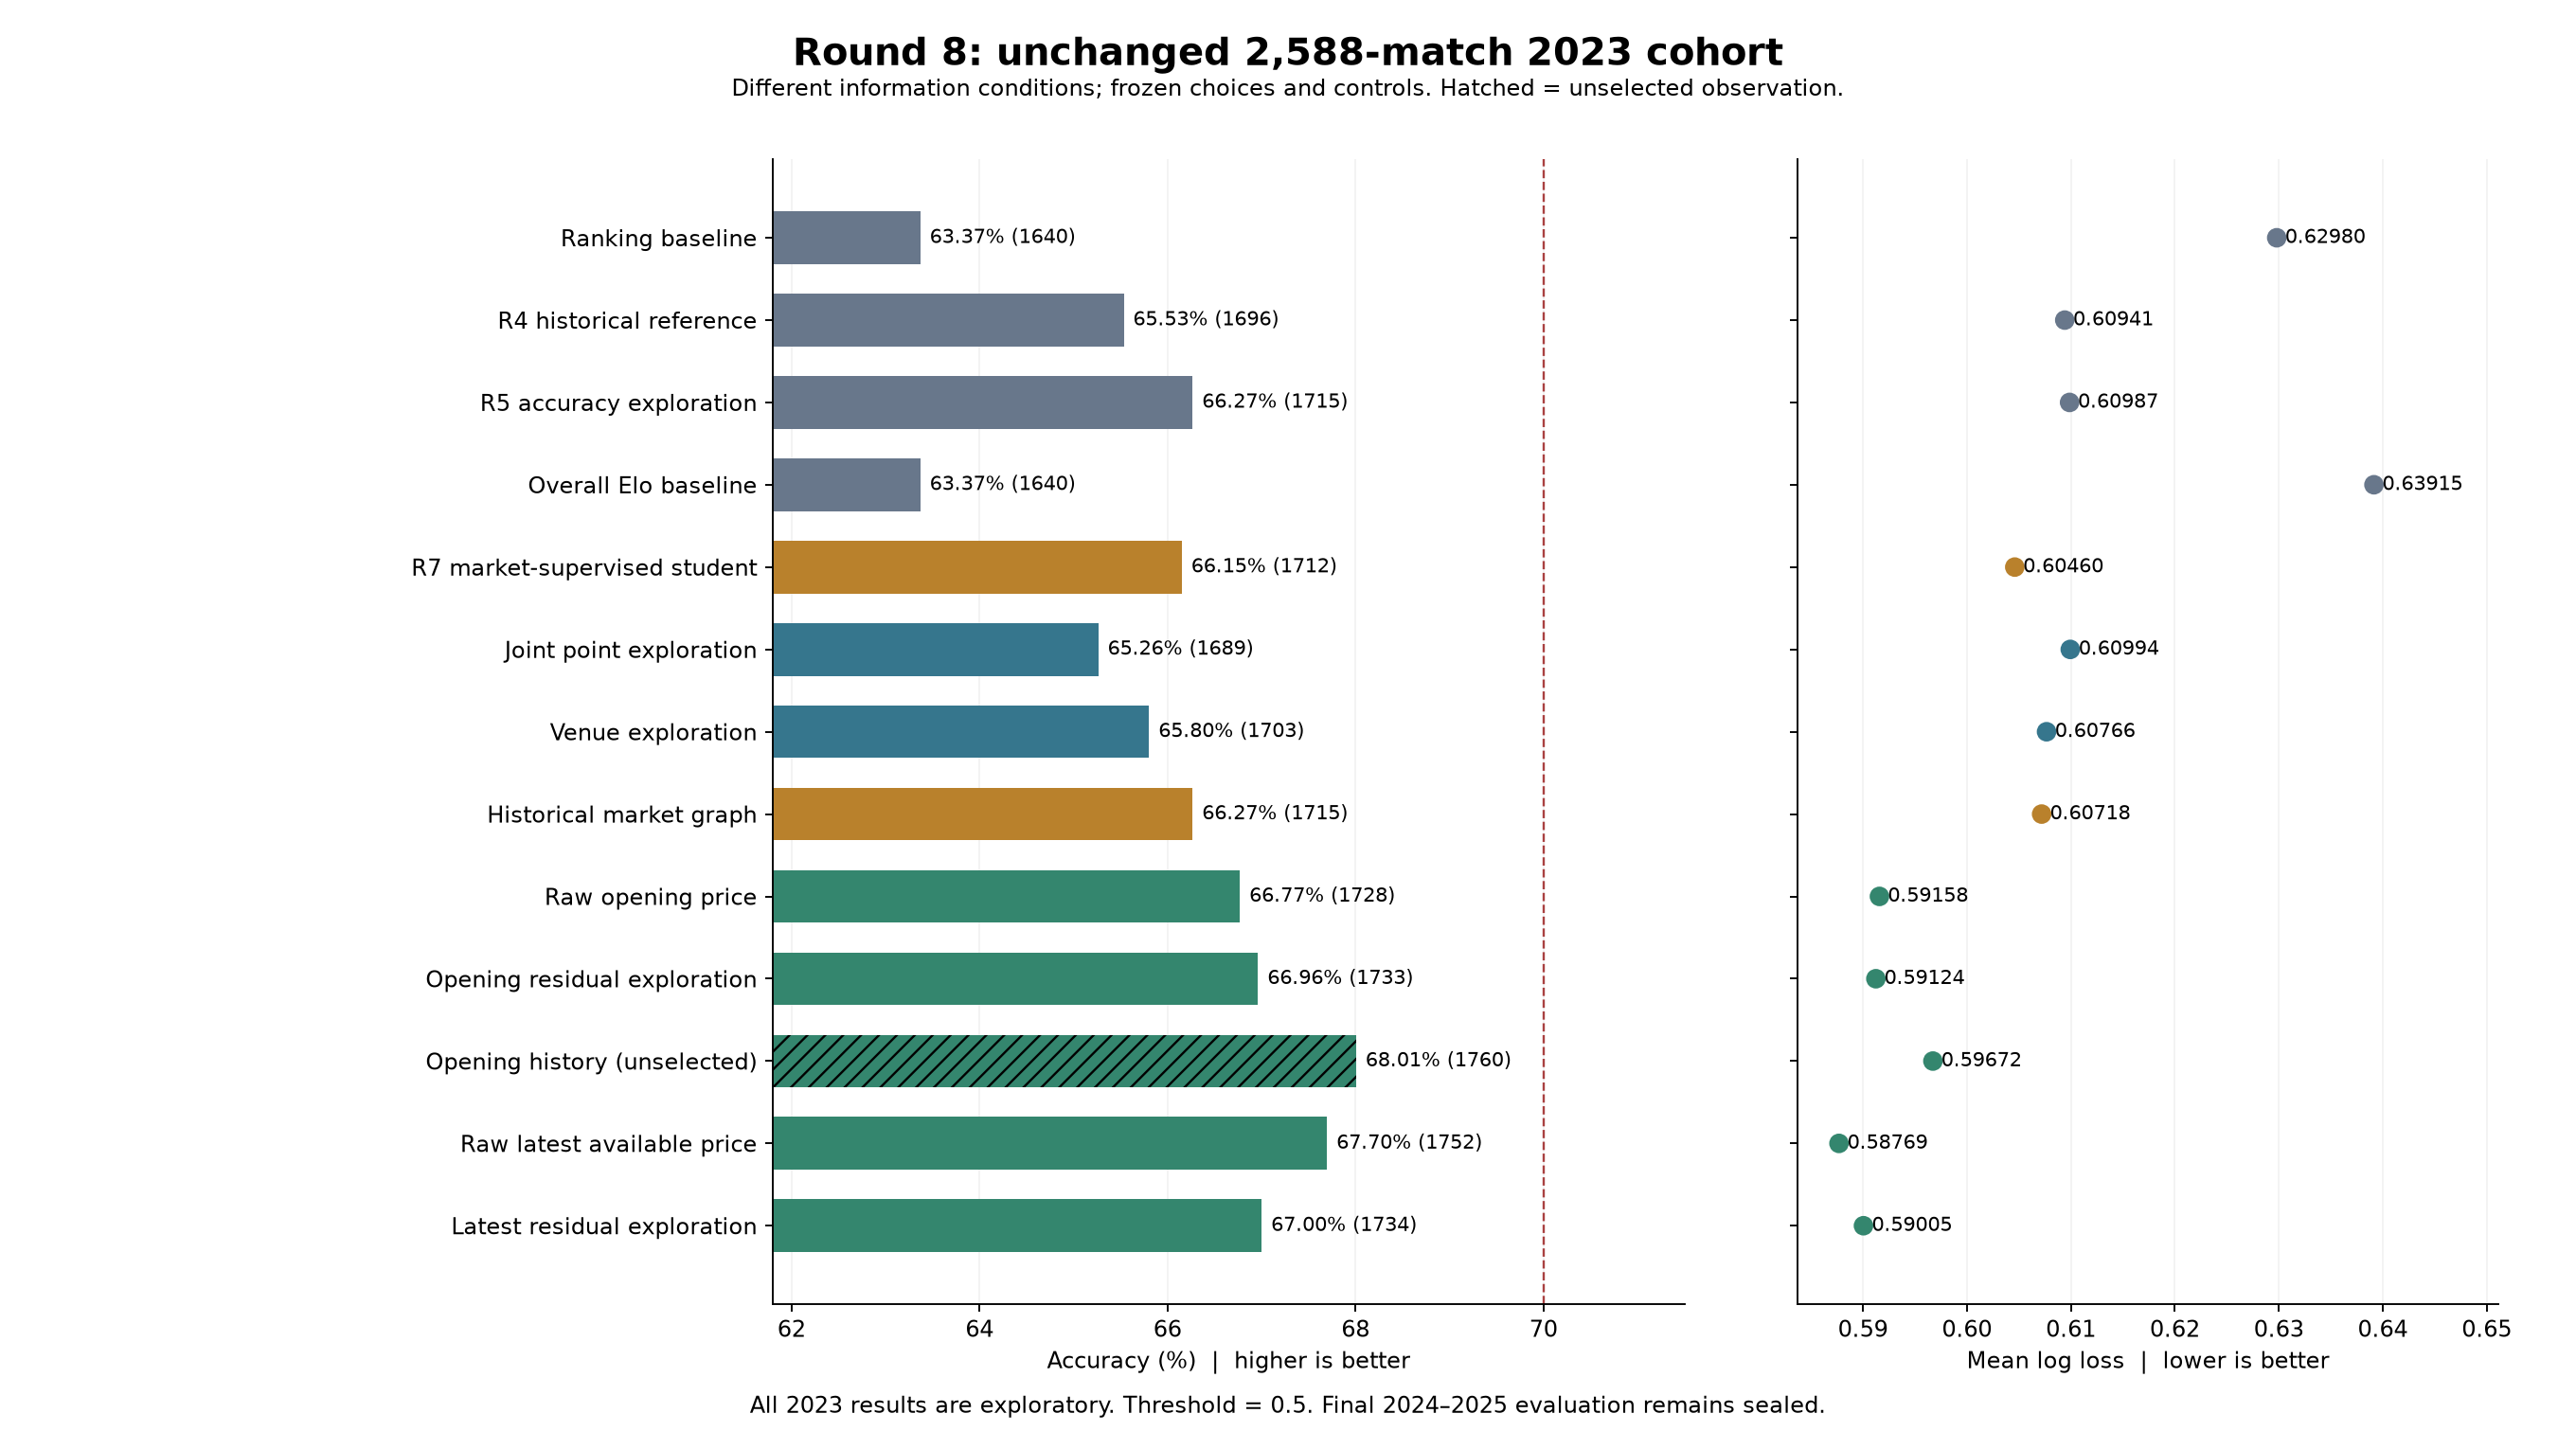

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
out = Path.cwd()/'results/round8'
table = pd.read_csv(out/'overview_comparison.csv')
assert table.matches.eq(2588).all()
display(table.loc[table.display,['branch','model','role','correct','accuracy','mean_log_loss']])
display(Image(filename=str(out/'round8_comparison.png')))

## 全部冻结输出

包括未选中控制与旧参考；不根据2023重新选择。

In [2]:
with pd.option_context('display.max_rows',200,'display.max_colwidth',60):
    display(table[['branch','model','role','correct','accuracy','mean_log_loss']])

,branch,model,role,correct,accuracy,mean_log_loss
0,baseline,rank_reference,排名 logistic 原基准,1640,0.633694,0.629796
1,baseline,previous_probability_recommendation,R4：保留的纯历史概率推荐,1696,0.655332,0.609407
2,baseline,previous_round5_exploration,R5：冻结准确率探索组合,1715,0.662674,0.609871
3,baseline,previous_round5_best_loss,R5：此前最低观察 loss 对照,1706,0.659196,0.606453
4,baseline,raw_elo_k32_diff,整体 Elo 原基准（开发期选 K=32）,1640,0.633694,0.639146
5,student,market_lambda1,R7：市场监督学生,1712,0.661515,0.604599
6,joint_points,joint_surface_event_r4blend0.5,固定对照 / 既有模型,1717,0.663447,0.612987
7,joint_points,round5_pooled_comparator,固定对照 / 既有模型,1715,0.662674,0.609871
8,joint_points,joint_surface_r4blend0.5,固定对照 / 既有模型,1713,0.661901,0.613132
9,joint_points,round5_probability_comparator,固定对照 / 既有模型,1706,0.659196,0.606453


## 同一学习器/结构的对照

不同信息条件、CV与2023分开；这些相关比较不是独立重复实验。

In [3]:
for branch,filename in [('joint_points','matched_controls.csv'),('venue','matched_controls.csv'),('market_residual/opening','matched_information_controls.csv'),('market_residual/latest','matched_information_controls.csv')]:
    print(branch)
    controls = pd.read_csv(out/branch/filename)
    with pd.option_context('display.max_rows',100):
        display(controls)

joint_points


,contrast,baseline,candidate,period,matches,accuracy_gain,log_loss_reduction
0,opponent_adjustment,serve_only_recent,joint_recent,pooled,6130,0.046330,0.041099
1,recency,joint_static,joint_recent,pooled,6130,0.008809,0.011969
2,surface_preference,joint_recent,joint_surface,pooled,6130,0.001794,0.002005
3,event_intercept,joint_surface,joint_surface_event,pooled,6130,-0.000326,-0.000036
4,opponent_adjustment,serve_only_recent,joint_recent,2020,1214,0.034596,0.038534
5,recency,joint_static,joint_recent,2020,1214,0.004119,0.011797
6,surface_preference,joint_recent,joint_surface,2020,1214,0.000824,0.005767
7,event_intercept,joint_surface,joint_surface_event,2020,1214,0.000824,-0.000164
8,opponent_adjustment,serve_only_recent,joint_recent,2021,2388,0.040201,0.038483
9,recency,joint_static,joint_recent,2021,2388,0.010050,0.014408


venue


,candidate,control,oof_accuracy_change,oof_loss_change,validation_accuracy_change,validation_loss_change
0,venue_surface_linear,venue_base_linear,0.002121,-0.000061,0.000773,0.000543
1,venue_raw_linear,venue_surface_linear,-0.000163,0.000203,-0.003478,0.000598
2,venue_adjusted_linear,venue_surface_linear,-0.000653,0.000294,-0.001932,0.000113
3,venue_adjusted_linear,venue_raw_linear,-0.000489,0.000091,0.001546,-0.000486
4,venue_adjusted_linear,venue_strength_linear,-0.002121,0.000567,-0.000386,-0.000615
5,venue_surface_spline,venue_base_spline,-0.002447,-0.000015,0.000773,0.000528
6,venue_raw_spline,venue_surface_spline,0.004078,0.000182,-0.001932,0.000619
7,venue_adjusted_spline,venue_surface_spline,0.001468,0.000316,0.000000,0.000051
8,venue_adjusted_spline,venue_raw_spline,-0.002610,0.000134,0.001932,-0.000569
9,venue_adjusted_spline,venue_strength_spline,-0.001468,0.000586,0.002318,-0.000719


market_residual/opening


,condition,information_change,learner,alpha,period,matches,base,candidate,accuracy_gain,log_loss_reduction
0,opening,price_to_history,linear_C0.003,0.25,2021H2,911,price_linear_C0.003_alpha0.25,history_linear_C0.003_alpha0.25,0.008782,0.000334
1,opening,price_to_history,linear_C0.003,0.25,2022,2528,price_linear_C0.003_alpha0.25,history_linear_C0.003_alpha0.25,-0.002769,0.000213
2,opening,price_to_history,linear_C0.003,0.25,pooled,3439,price_linear_C0.003_alpha0.25,history_linear_C0.003_alpha0.25,0.000291,0.000245
3,opening,price_to_history,linear_C0.003,0.25,2023_exploratory,2588,price_linear_C0.003_alpha0.25,history_linear_C0.003_alpha0.25,0.001546,0.000470
4,opening,price_to_history,linear_C0.003,0.50,2021H2,911,price_linear_C0.003_alpha0.5,history_linear_C0.003_alpha0.5,0.006586,0.000252
5,opening,price_to_history,linear_C0.003,0.50,2022,2528,price_linear_C0.003_alpha0.5,history_linear_C0.003_alpha0.5,-0.003956,-0.000112
6,opening,price_to_history,linear_C0.003,0.50,pooled,3439,price_linear_C0.003_alpha0.5,history_linear_C0.003_alpha0.5,-0.001163,-0.000015
7,opening,price_to_history,linear_C0.003,0.50,2023_exploratory,2588,price_linear_C0.003_alpha0.5,history_linear_C0.003_alpha0.5,0.003091,0.000459
8,opening,price_to_history,linear_C0.003,1.00,2021H2,911,price_linear_C0.003_alpha1,history_linear_C0.003_alpha1,0.015368,-0.001132
9,opening,price_to_history,linear_C0.003,1.00,2022,2528,price_linear_C0.003_alpha1,history_linear_C0.003_alpha1,-0.005538,-0.002332


market_residual/latest


,condition,information_change,learner,alpha,period,matches,base,candidate,accuracy_gain,log_loss_reduction
0,latest,price_to_history,linear_C0.003,0.25,2021H2,911,price_linear_C0.003_alpha0.25,history_linear_C0.003_alpha0.25,0.008782,0.000334
1,latest,price_to_history,linear_C0.003,0.25,2022,2528,price_linear_C0.003_alpha0.25,history_linear_C0.003_alpha0.25,0.001187,0.000131
2,latest,price_to_history,linear_C0.003,0.25,pooled,3439,price_linear_C0.003_alpha0.25,history_linear_C0.003_alpha0.25,0.003199,0.000185
3,latest,price_to_history,linear_C0.003,0.25,2023_exploratory,2588,price_linear_C0.003_alpha0.25,history_linear_C0.003_alpha0.25,-0.003864,0.000446
4,latest,price_to_history,linear_C0.003,0.50,2021H2,911,price_linear_C0.003_alpha0.5,history_linear_C0.003_alpha0.5,0.006586,0.000252
5,latest,price_to_history,linear_C0.003,0.50,2022,2528,price_linear_C0.003_alpha0.5,history_linear_C0.003_alpha0.5,0.002373,-0.000269
6,latest,price_to_history,linear_C0.003,0.50,pooled,3439,price_linear_C0.003_alpha0.5,history_linear_C0.003_alpha0.5,0.003489,-0.000131
7,latest,price_to_history,linear_C0.003,0.50,2023_exploratory,2588,price_linear_C0.003_alpha0.5,history_linear_C0.003_alpha0.5,-0.005023,0.000440
8,latest,price_to_history,linear_C0.003,1.00,2021H2,911,price_linear_C0.003_alpha1,history_linear_C0.003_alpha1,0.015368,-0.001132
9,latest,price_to_history,linear_C0.003,1.00,2022,2528,price_linear_C0.003_alpha1,history_linear_C0.003_alpha1,-0.001187,-0.002619
